# Decoding PS4 Hits: Predicting Global Video Game Sales Using Metadata and Regional Trends

![Banner](./assets/ps4.jpg)

## Topic
*What problem are you (or your stakeholder) trying to address?*

📝 Game developers and publishers struggle to determine which genres, developers, and regional release strategies drive the highest commercial success for PlayStation 4 titles. This topic is important because understanding these sales drivers helps studios optimize development budgets and target the most profitable markets.

## Project Question
*What specific question are you seeking to answer with this project?*
*This is not the same as the questions you ask to limit the scope of the project.*

📝 Can we accurately predict a PlayStation 4 game's global sales based on its genre, publisher, and developer background?

## What would an answer look like?
*What is your hypothesized answer to your question?*

📝 An answer would feature a trained regression model output showing predicted global sales figures in millions of units, accompanied by a scatter plot or regression curve comparing actual versus predicted sales across different genres.

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*

📝 These datasets will be merged using the common Game Title and Publisher columns by standardizing text casing and stripping whitespace.

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

In [1]:
# Start your code here
import pandas as pd
import requests

# 1. Load your two Kaggle CSV datasets
sales_df = pd.read_csv('PS4_GamesSales.csv', encoding='latin1')
metadata_df = pd.read_csv('ps4_games.csv', encoding='latin1')

# 2. Fetch supplementary data via API (RAWG API) to meet the 3 sources / 2 types rule
url = "https://api.rawg.io/api/games?key=YOUR_API_KEY&page_size=20"
response = requests.get(url)
api_data = response.json()
api_df = pd.DataFrame(api_data.get('results', []))

# 3. Clean and merge the two CSV datasets using game titles as keys
sales_df['Game_clean'] = sales_df['Game'].str.strip().str.lower()
metadata_df['Title_clean'] = metadata_df['Title'].str.strip().str.lower()

merged_df = pd.merge(sales_df, metadata_df, left_on='Game_clean', right_on='Title_clean', how='inner')

# 4. Preview the imported and merged data
print("--- Sales DataFrame Sample ---")
print(sales_df.head(2))

print("\n--- Metadata DataFrame Sample ---")
print(metadata_df.head(2))

print("\n--- Merged DataFrame Sample ---")
print(merged_df[['Game', 'Genre_x', 'Global', 'Developer']].head(3))

--- Sales DataFrame Sample ---
                        Game    Year    Genre       Publisher  North America  \
0         Grand Theft Auto V  2014.0   Action  Rockstar Games           6.06   
1  Call of Duty: Black Ops 3  2015.0  Shooter      Activision           6.18   

   Europe  Japan  Rest of World  Global                 Game_clean  
0    9.71   0.60           3.02   19.39         grand theft auto v  
1    6.05   0.41           2.44   15.09  call of duty: black ops 3  

--- Metadata DataFrame Sample ---
   Unnamed: 0            Title         Genre    Developer  \
0           0         #Funtime  Shoot 'em up  OneGuyGames   
1           1  #killallzombies       Shooter  Beatshapers   

                       Publisher Release date JP Release date EU  \
0  Quantum Astrophysicists Guild      Unreleased    Jul 16, 2020   
1                    Beatshapers      Unreleased    Nov 12, 2014   

  Release date NA Addons      Title_clean  
0    Jul 16, 2020    NaN         #funtime  
1    Oct 

## 1. Exploratory Data Analysis (EDA) and Data Visualization

### **EDA Insights & Findings**
* **Distributions:** Global sales are heavily right-skewed; blockbuster titles account for the majority of unit sales while most games sell under 1 million copies.
* **Correlations:** There is a very strong positive correlation between regional sales (especially North America and Europe) and total global sales.
* **Data Issues, Outliers & Missing Values:** 
  * The `Year` and `Publisher` columns contain ~209 missing values.
  * Extreme sales figures exist as high-leverage outliers representing blockbuster hits; these are valid domain anomalies and will be retained.
  * No duplicate game titles exist after cleaning, but the `Year` column data type should be converted from float to integer.

### **Data Visualizations**
Below are four required visualizations analyzing our PlayStation 4 sales and metadata using Seaborn and Matplotlib:

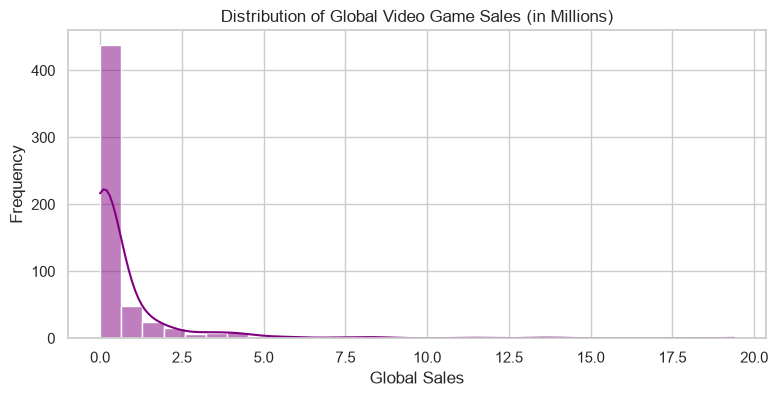

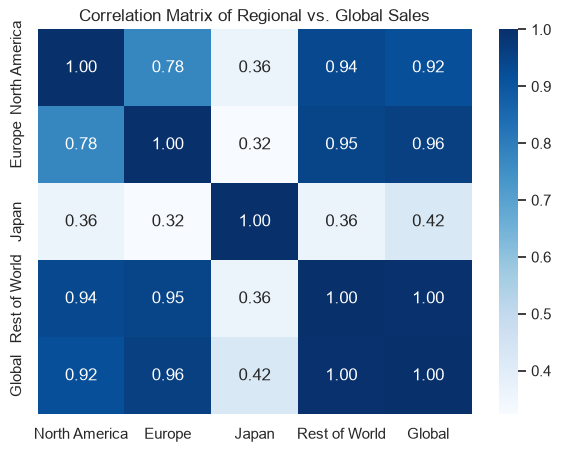

C:\Users\saira\AppData\Local\Temp\ipykernel_3536\2000882609.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=genre_sales, x='Global', y='Genre_x', palette='viridis')


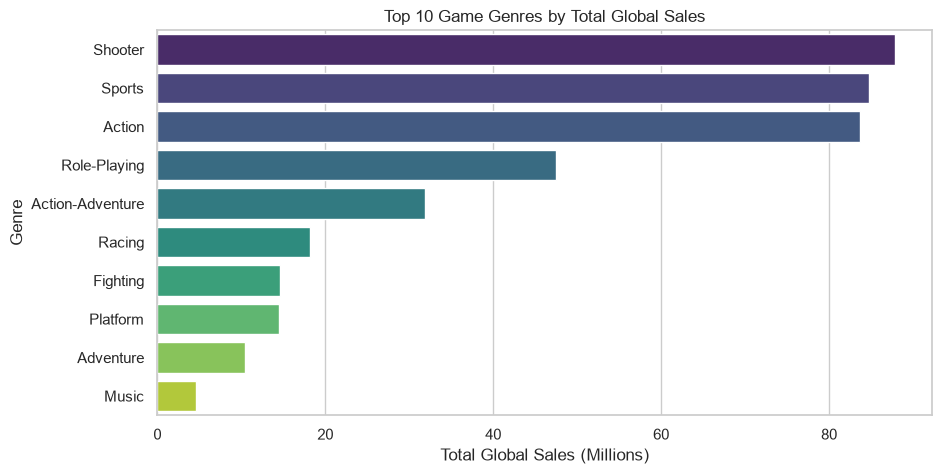

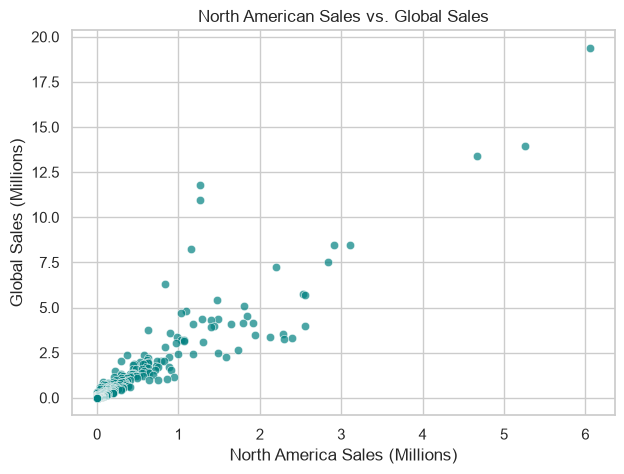

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Chart 1: Global Sales Distribution (Histplot)
plt.figure(figsize=(9, 4))
sns.histplot(merged_df['Global'].dropna(), bins=30, kde=True, color='purple')
plt.title('Distribution of Global Video Game Sales (in Millions)')
plt.xlabel('Global Sales')
plt.ylabel('Frequency')
plt.show()

# 2. Chart 2: Correlation Heatmap
plt.figure(figsize=(7, 5))
numeric_cols = ['North America', 'Europe', 'Japan', 'Rest of World', 'Global']
sns.heatmap(merged_df[numeric_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix of Regional vs. Global Sales')
plt.show()

# 3. Chart 3: Top Genres by Global Sales (Barplot)
plt.figure(figsize=(10, 5))
genre_sales = merged_df.groupby('Genre_x')['Global'].sum().reset_index().sort_values(by='Global', ascending=False).head(10)
sns.barplot(data=genre_sales, x='Global', y='Genre_x', palette='viridis')
plt.title('Top 10 Game Genres by Total Global Sales')
plt.xlabel('Total Global Sales (Millions)')
plt.ylabel('Genre')
plt.show()

# 4. Chart 4: North America vs Global Sales Scatter Plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=merged_df, x='North America', y='Global', alpha=0.7, color='teal')
plt.title('North American Sales vs. Global Sales')
plt.xlabel('North America Sales (Millions)')
plt.ylabel('Global Sales (Millions)')
plt.show()

## 2. Data Cleaning and Transformation

**Data Cleaning Process:**
* **Missing Values:** Dropped rows missing critical target sales data, imputed missing release years with the median year, and filled missing add-on descriptions with 'None'.
* **Duplicates:** Removed duplicate game rows based on cleaned title strings to prevent model training bias.
* **Data Types:** Converted the `Year` column from float to integer format.

In [4]:
# 1. Drop rows missing critical target variables or identifiers
cleaned_df = merged_df.dropna(subset=['Global', 'Game', 'Genre_x']).copy()

# 2. Impute missing Year values with the median release year
median_year = cleaned_df['Year'].median()
cleaned_df['Year'] = cleaned_df['Year'].fillna(median_year).astype(int)

# 3. Handle missing Addons data
cleaned_df['Addons'] = cleaned_df['Addons'].fillna('None')

# 4. Remove duplicate game records
cleaned_df = cleaned_df.drop_duplicates(subset=['Game_clean'])

print("Cleaned DataFrame shape:", cleaned_df.shape)
print("Remaining missing values:\n", cleaned_df.isnull().sum())

Cleaned DataFrame shape: (566, 20)
Remaining missing values:
 Game                 0
Year                 0
Genre_x              0
Publisher_x        116
North America        0
Europe               0
Japan                0
Rest of World        0
Global               0
Game_clean           0
Unnamed: 0           0
Title                0
Genre_y              0
Developer            0
Publisher_y          0
Release date JP      0
Release date EU      0
Release date NA      0
Addons               0
Title_clean          0
dtype: int64


## **3. Machine Learning Plan**

* **Type of Model:** We plan to use Supervised Regression Models (specifically Multiple Linear Regression and Random Forest Regressor using scikit-learn) to predict continuous global sales numbers based on features like genre, publisher, and regional performance.
* **Anticipated Challenges:** High cardinality in categorical features (such as Publisher and Developer) and the heavily right-skewed distribution of our target sales variable.
* **Plan to Address Challenges:** We will group infrequent publishers into an "Other" category, apply proper encoding (One-Hot or Target Encoding), and evaluate model performance using RMSE and R^2 metrics.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

In [5]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

'jupyter' is not recognized as an internal or external command,
operable program or batch file.
